COU07506_Week02_250242464014

PRE-LAB PREPARATION

Question (a): A 7 kHz tone is sampled at 10 kHz. What frequency appears?

Given:

Original frequency, F = 7 kHz

Sampling frequency, fs = 10 kHz

The Nyquist frequency is:

fs / 2 = 10 / 2 = 5 kHz

Since the original frequency (7 kHz) is greater than the Nyquist frequency (5 kHz), aliasing occurs.

Alias frequency:

F_alias = |F - fs|

F_alias = |7 - 10| = 3 kHz

Therefore, the frequency that appears is 3 kHz.

PRE-LAB PREPARATION

Question (b): Compute Δ and the theoretical SQNR for an 8-bit quantizer with a ±1 V range.
Given:

Number of bits, B = 8

Quantizer range = ±1 V

Maximum amplitude, Xm = 1 V

Step 1: Calculate the quantization step size (Δ).

Δ = 2Xm / 2^B

Δ = 2(1) / 2^8

Δ = 2 / 256

Δ = 0.0078125 V

Step 2: Calculate theoretical SQNR.

SQNR = 6.02B + 1.76 dB

SQNR = 6.02(8) + 1.76

SQNR = 48.16 + 1.76

SQNR = 49.92 dB

Therefore:

Quantization step size (Δ) = 0.0078125 V

Theoretical SQNR = 49.92 dB

Task 2.1 — Aliasing of a Sinusoid

In this task, a sinusoidal signal with an original frequency of 7 Hz is sampled at different sampling frequencies to demonstrate the effect of aliasing. The sampling frequencies used are 10 Hz, 12 Hz, 14 Hz, and 20 Hz. The alias frequency is calculated for each sampling frequency and the results are recorded in a table. This experiment helps demonstrate how the sampling frequency affects the representation of a signal and how aliasing occurs when the sampling rate is insufficient.

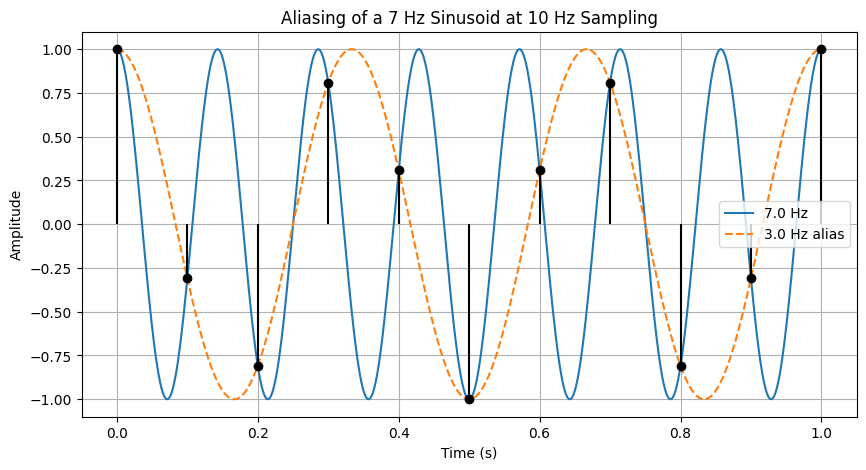

Original frequency = 7.0 Hz
Sampling frequency = 10.0 Hz
Alias frequency = 3.0 Hz


In [1]:

import numpy as np
import matplotlib.pyplot as plt

f0, fs = 7.0, 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs * round(f0 / fs))

plt.figure(figsize=(10, 5))

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--",
         label=f"{f_alias} Hz alias")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Aliasing of a 7 Hz Sinusoid at 10 Hz Sampling")
plt.legend()
plt.grid()
plt.show()

print("Original frequency =", f0, "Hz")
print("Sampling frequency =", fs, "Hz")
print("Alias frequency =", f_alias, "Hz")


Repeat with \(f_s = 12,\ 14,\ 20\) Hz

In [2]:

sampling_rates = [12, 14, 20]

for fs in sampling_rates:
    f_alias = abs(f0 - fs * round(f0 / fs))
    print("Sampling frequency:", fs, "Hz",
          "| Alias frequency:", f_alias, "Hz")


Sampling frequency: 12 Hz | Alias frequency: 5.0 Hz
Sampling frequency: 14 Hz | Alias frequency: 7.0 Hz
Sampling frequency: 20 Hz | Alias frequency: 7.0 Hz


Alias Frequency Results

| Sampling Frequency (Hz) | Calculated Alias Frequency (Hz) |
|---:|---:|
| 10 | 3 |
| 12 | 5 |
| 14 | 7 |
| 20 | 7 |

Comparison with the formula:

The calculated alias frequencies agree with the aliasing formula. When the sampling frequency is 10 Hz, the 7 Hz signal appears at 3 Hz. At 12 Hz, it appears at 5 Hz. At 14 Hz and 20 Hz, it remains at 7 Hz because the sampling frequencies are sufficient to represent the 7 Hz signal without folding below the Nyquist frequency.

Task 2.2 — Hear Aliasing

In this task, we use the voice recording from Week 1 to demonstrate aliasing in audio signals. First, we load the recorded audio and check its sampling frequency. If the audio is stereo, it is converted into mono. The signal is then normalized so that its amplitude is within the range of -1 to 1.

If the voice recording is not available, a fallback chirp signal is generated for the experiment.

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display
import os


In [6]:

import os

fname = "DSP.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

print("Original sampling frequency =", fs, "Hz")
print("Number of audio samples =", len(x))
print("Audio duration =", len(x)/fs, "seconds")


Original sampling frequency = 44100 Hz
Number of audio samples = 132300
Audio duration = 3.0 seconds


Downsampling the Audio Signal and Comparing Aliasing Effects

In this step, the audio signal is downsampled using factors of 2, 4, and 8. First, samples are removed without applying a filter (naive downsampling). Then, the same signal is downsampled using an anti-aliasing low-pass filter with signal.decimate. The two versions are compared to understand the effect of aliasing.

In [7]:

for k in [2, 4, 8]:
    naive = x[::k]  # No filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")  # Low-pass filter, then downsample

    print(k, "new fs =", fs // k, "Hz")


2 new fs = 22050 Hz
4 new fs = 11025 Hz
8 new fs = 5512 Hz


In [8]:

k = 8

naive = x[::k]
proper = signal.decimate(x, k, ftype="fir")

print("Naive downsampling:")
display(Audio(naive, rate=fs//k))

print("Proper downsampling:")
display(Audio(proper, rate=fs//k))


Naive downsampling:


Proper downsampling:


Listening Observation (k = 8):

The naive downsampled audio sounded louder and more distorted compared to the original recording. The properly downsampled audio sounded softer or faded. This is because naive downsampling does not use an anti-aliasing filter, while proper downsampling applies a low-pass filter before reducing the sampling rate to minimize aliasing.

Task 2.3 — Uniform Quantizer
In this task, a uniform quantizer is implemented to convert a continuous range of signal amplitudes into a limited number of discrete amplitude levels. A 3-bit quantizer is applied to a 300 Hz sine wave sampled at 8000 Hz. The original signal, quantized signal, and quantization error are then plotted to observe the effect of quantization.

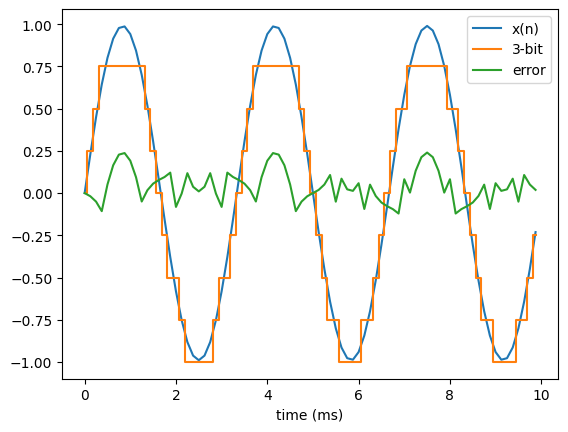

In [9]:

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)")
plt.legend()
plt.show()


Task 2.4 — Verify the 6 dB-per-bit Rule

In this task, the Signal-to-Quantization-Noise Ratio (SQNR) is measured for different quantization bit depths ranging from 2 to 16 bits. The measured SQNR values are compared with the theoretical SQNR calculated using the formula 6.02B + 1.76 dB. A graph is plotted to verify whether adding one bit increases the SQNR by approximately 6 dB.

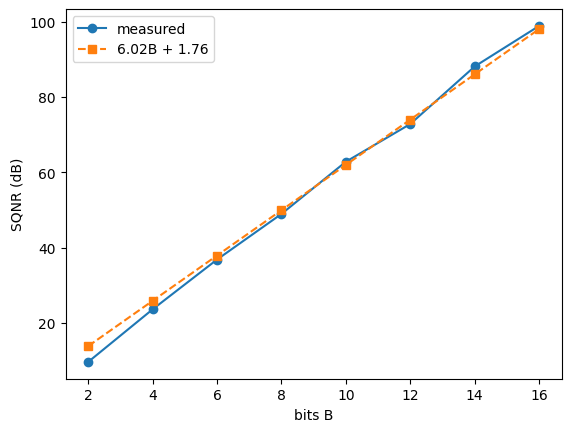

In [10]:

bits = np.arange(2, 17, 2)

meas = [
    10*np.log10(np.sum(x**2) / np.sum((x - quantize(x, B))**2))
    for B in bits
]

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")

plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.show()


Observation:

The graph shows that the SQNR increases as the number of quantization bits increases. The measured SQNR generally follows the theoretical SQNR curve. This demonstrates that increasing the number of bits improves quantization accuracy and reduces quantization noise.

Task 2.5 — Quantize Your Voice

In this task, the voice recording from Week 1 is quantized using 4-bit, 8-bit, and 12-bit quantizers. Each quantized audio signal is played back and compared with the original recording. The SQNR is also calculated for each bit depth to evaluate the effect of quantization on speech quality.

In [12]:

import os
print(os.listdir())


['.config', 'DSP (1).wav', 'sample_data']


In [13]:

# Load the original voice recording again
fs_voice, voice = wavfile.read("DSP (1).wav")

# Convert stereo audio to mono if necessary
voice = voice.mean(axis=1) if voice.ndim > 1 else voice.astype(float)

# Normalize the audio
voice = voice / np.max(np.abs(voice))

# Quantize the voice using 4, 8 and 12 bits
for B in [4, 8, 12]:
    voice_q = quantize(voice, B)

    error = voice - voice_q
    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    print(f"{B}-bit SQNR = {sqnr:.2f} dB")

    display(Audio(voice_q, rate=fs_voice))


4-bit SQNR = 14.34 dB


8-bit SQNR = 37.84 dB


12-bit SQNR = 61.93 dB


Observation

Observation: The 4-bit quantized voice had more noticeable distortion and lower audio quality. The 8-bit version had better quality, while the 12-bit version sounded closer to the original recording. The SQNR increased as the number of quantization bits increased. This shows that using more bits reduces quantization noise and improves speech quality.

Analysis Questions

Question 1

Explain with a frequency-axis sketch why a 7 Hz tone appears at 3 Hz when fs = 10 Hz
When a 7 Hz tone is sampled at 10 Hz, the Nyquist frequency is 5 Hz. Since 7 Hz is above the Nyquist frequency, aliasing occurs. The alias frequency is calculated as:

f_{alias}=|f_s-f|=|10-7|=3{ Hz}

Therefore, the 7 Hz tone appears as a 3 Hz tone after sampling.
0       3       5       7       10 Hz
|-------|-------|-------|--------|
        ↑               ↑
    Alias (3 Hz)    Original (7 Hz)

Question 2

In Task 2.2, why can aliasing heard in the naïve version not be removed afterwards?

Aliasing cannot be removed after naïve downsampling because the high-frequency components have already been incorrectly represented as lower frequencies. Once aliasing occurs, the original frequency information is lost. An anti-aliasing low-pass filter must be applied before downsampling to prevent this problem.

Question 3

By how much does SQNR change when one bit is added? Does your measurement agree?

When one quantization bit is added, the SQNR increases by approximately 6.02 dB. My measurements agree with this rule because the SQNR increases as the number of bits increases. This means that adding more bits reduces quantization noise and improves signal quality.

Question 4

A temperature sensor changes by at most 0.1 °C per second and required resolution 0.01 °C over range 0–100 °C. Suggest sampling rate and number of bits, justify.

A suitable sampling rate is at least 2 samples per second (2 Hz), based on the Nyquist sampling principle for a maximum signal frequency of 0.1 Hz. A sampling rate of 10 Hz would be safer to capture temperature changes accurately.

For the number of bits:

Δ = 100 / 2^B ≤ 0.01
2^B ≥ 100 / 0.01
2^B ≥ 10,000
B ≥ log₂(10,000)
B ≥ 13.29

Therefore, at least 14 bits are required to achieve a resolution of 0.01 °C over the 0–100 °C range.

AI Use Statement

AI tools were used to assist in understanding the laboratory instructions, explaining DSP concepts, troubleshooting Python code, and improving the presentation of answers. All code was executed and results were reviewed by the student.